=== KARAR DESTEK SİSTEMİ ANALİZ ÇIKTISI ===


,Sporcu_ID,Brans,Sakatlik,Risk_Skoru,Risk_Durumu,Sistem_Onerisi
0,SP-101,Futbol,Ön Çapraz Bağ,78.83,Yüksek Risk,ACİL MÜDAHALE: Uzman spor psikoloğu ile birebi...
1,SP-102,Basketbol,Ayak Bileği Burkulması,34.49,Düşük Risk,Standart rehabilitasyon ve takım içi motivasyo...
2,SP-103,Voleybol,Omuz Tendiniti,61.16,Orta Risk,Antrenör gözetiminde kademeli dönüş ve haftalı...
3,SP-104,Atletizm,Hamstring Yırtığı,41.33,Orta Risk,Antrenör gözetiminde kademeli dönüş ve haftalı...
4,SP-105,Tenis,Menisküs,78.49,Yüksek Risk,ACİL MÜDAHALE: Uzman spor psikoloğu ile birebi...


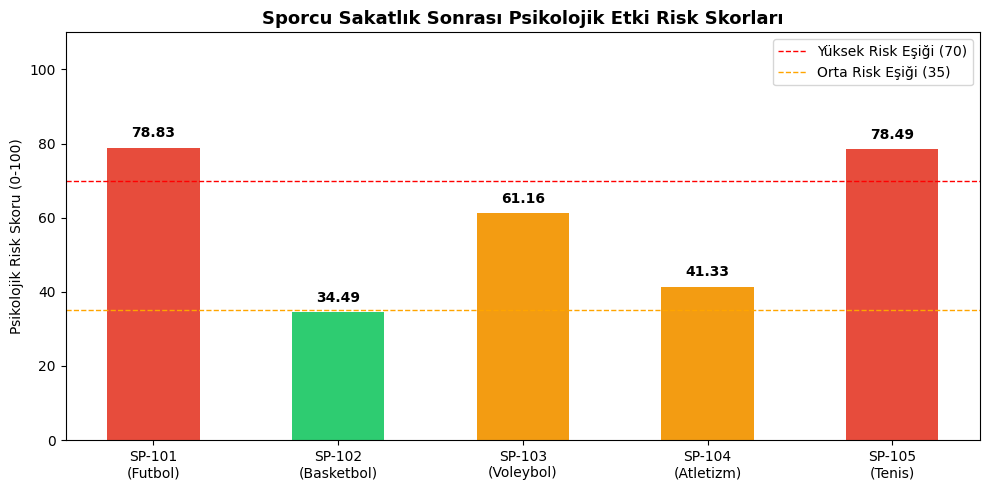

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. KARAR DESTEK SİSTEMİ ÇEKİRDEK ALGORİTMASI
class PsikolojikDegerlendirmeSistemi:

  def __init__(self):
    # Risk eşik değerleri (0 - 100 ölçeği)
    self.dusuk_esik = 35
    self.yuksek_esik = 70

  def risk_skoru_hesapla(
      self,
      sakatlik_suresi_gun,
      tekrar_sayisi,
      kaygi_puani,
      motivasyon_kaybi,
      ozguven_eksikligi,
  ):
    """
        Sporcunun fiziksel sakatlık geçmişi ve psikolojik ölçek puanlarına göre
        ağırlıklı Psikolojik Etki Risk Skoru (0-100) hesaplar.
        """
    # Fiziksel yük faktörü (maksimum 30 puan)
    fiziksel_etki = min((sakatlik_suresi_gun / 180) * 20, 20) + min(
        tekrar_sayisi * 3.33, 10
    )

    # Psikolojik ölçek faktörü (1-10 arası girilen puanların ağırlıklı toplamı, maks 70 puan)
    psikolojik_etki = (
        (kaygi_puani * 2.5)
        + (motivasyon_kaybi * 2.5)
        + (ozguven_eksikligi * 2.0)
    )

    toplam_skor = round(min(fiziksel_etki + psikolojik_etki, 100), 2)
    return toplam_skor

  def karar_destek_onerisi(self, skor):
    if skor < self.dusuk_esik:
      return (
          "Düşük Risk",
          "Standart rehabilitasyon ve takım içi motivasyon desteği yeterlidir.",
      )
    elif skor < self.yuksek_esik:
      return (
          "Orta Risk",
          "Antrenör gözetiminde kademeli dönüş ve haftalık psikolojik takip"
          " önerilir.",
      )
    else:
      return (
          "Yüksek Risk",
          "ACİL MÜDAHALE: Uzman spor psikoloğu ile birebir terapi ve sahaya"
          " dönüş ertelemesi önerilir.",
      )


# 2. ÖRNEK SPORCU VERİ SETİ İLE SİSTEM TESTİ
sistem = PsikolojikDegerlendirmeSistemi()

ornek_sporcular = [
    {
        "Sporcu_ID": "SP-101",
        "Brans": "Futbol",
        "Sakatlik": "Ön Çapraz Bağ",
        "Sure_Gun": 180,
        "Tekrar": 1,
        "Kaygi": 8,
        "Motivasyon_Kaybi": 7,
        "Ozguven_Eksikligi": 9,
    },
    {
        "Sporcu_ID": "SP-102",
        "Brans": "Basketbol",
        "Sakatlik": "Ayak Bileği Burkulması",
        "Sure_Gun": 21,
        "Tekrar": 2,
        "Kaygi": 4,
        "Motivasyon_Kaybi": 3,
        "Ozguven_Eksikligi": 4,
    },
    {
        "Sporcu_ID": "SP-103",
        "Brans": "Voleybol",
        "Sakatlik": "Omuz Tendiniti",
        "Sure_Gun": 60,
        "Tekrar": 3,
        "Kaygi": 7,
        "Motivasyon_Kaybi": 6,
        "Ozguven_Eksikligi": 6,
    },
    {
        "Sporcu_ID": "SP-104",
        "Brans": "Atletizm",
        "Sakatlik": "Hamstring Yırtığı",
        "Sure_Gun": 45,
        "Tekrar": 1,
        "Kaygi": 5,
        "Motivasyon_Kaybi": 5,
        "Ozguven_Eksikligi": 4,
    },
    {
        "Sporcu_ID": "SP-105",
        "Brans": "Tenis",
        "Sakatlik": "Menisküs",
        "Sure_Gun": 120,
        "Tekrar": 2,
        "Kaygi": 9,
        "Motivasyon_Kaybi": 8,
        "Ozguven_Eksikligi": 8,
    },
]

df = pd.DataFrame(ornek_sporcular)

# Her sporcu için sistem çıktısını hesapla
sonuclar = df.apply(
    lambda row: sistem.risk_skoru_hesapla(
        row["Sure_Gun"],
        row["Tekrar"],
        row["Kaygi"],
        row["Motivasyon_Kaybi"],
        row["Ozguven_Eksikligi"],
    ),
    axis=1,
)

df["Risk_Skoru"] = sonuclar
df[["Risk_Durumu", "Sistem_Onerisi"]] = pd.DataFrame(
    df["Risk_Skoru"].apply(sistem.karar_destek_onerisi).tolist(), index=df.index
)

print("=== KARAR DESTEK SİSTEMİ ANALİZ ÇIKTISI ===")
display(
    df[[
        "Sporcu_ID",
        "Brans",
        "Sakatlik",
        "Risk_Skoru",
        "Risk_Durumu",
        "Sistem_Onerisi",
    ]]
)

# 3. KARAR DESTEK GÖRSELLEŞTİRME PANELİ
plt.figure(figsize=(10, 5))
renkler = [
    "#e74c3c" if s >= 70 else "#f39c12" if s >= 35 else "#2ecc71"
    for s in df["Risk_Skoru"]
]
bars = plt.bar(
    df["Sporcu_ID"] + "\n(" + df["Brans"] + ")",
    df["Risk_Skoru"],
    color=renkler,
    width=0.5,
)

plt.axhline(
    y=70,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Yüksek Risk Eşiği (70)",
)
plt.axhline(
    y=35,
    color="orange",
    linestyle="--",
    linewidth=1,
    label="Orta Risk Eşiği (35)",
)
plt.title(
    "Sporcu Sakatlık Sonrası Psikolojik Etki Risk Skorları",
    fontsize=13,
    fontweight="bold",
)
plt.ylabel("Psikolojik Risk Skoru (0-100)")
plt.ylim(0, 110)
plt.legend()

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 2,
      f"{yval}",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.tight_layout()
plt.show()
